# Predicting English Premier League Match Outcomes

**Goal:** predict home win (`H`), draw (`D`) or away win (`A`) using only team form available before the match.

This notebook is the interactive companion to the project scripts. It calls the same data, feature and modelling functions so the notebook and command-line workflow stay consistent.

**Methodological guardrails**
- Never use final score, shots, cards, corners or betting odds as pre-match predictors.
- Team-form features are built from previous matches only.
- Split chronologically, not randomly.
- Use validation data for model selection and reserve the final seasons for one held-out evaluation.

In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent

# Ensure all relative paths resolve from the project root
os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import prepare_data
from src.features import build_features
from src.modeling import compare_models, FEATURE_COLUMNS, temporal_split

sns.set_theme(style="whitegrid")

## 1. Load and validate the data

The data is downloaded by season and cached locally. The first run needs an internet connection. The raw files are not committed to GitHub.

In [3]:
matches = prepare_data()
print(f"Rows: {len(matches):,}")
print(f"Date range: {matches['date'].min().date()} to {matches['date'].max().date()}")
print(f"Teams: {pd.concat([matches['home_team'], matches['away_team']]).nunique()}")
matches.head()

Rows: 5,700
Date range: 2010-08-14 to 2025-05-25
Teams: 41


,date,home_team,away_team,home_goals,away_goals,result,season_code,target,season
0,2010-08-14,Aston Villa,West Ham,3,0,H,1011,Home win,2010/11
1,2010-08-14,Blackburn,Everton,1,0,H,1011,Home win,2010/11
2,2010-08-14,Bolton,Fulham,0,0,D,1011,Draw,2010/11
3,2010-08-14,Chelsea,West Brom,6,0,H,1011,Home win,2010/11
4,2010-08-14,Sunderland,Birmingham,2,2,D,1011,Draw,2010/11


Check basic data quality before modelling. The outcome label is checked against the full-time score during cleaning.

In [4]:
display(matches[["date", "home_team", "away_team", "home_goals", "away_goals", "result"]].isna().sum())
display(matches["result"].value_counts().rename(index={"H":"Home win", "D":"Draw", "A":"Away win"}))

date          0
home_team     0
away_team     0
home_goals    0
away_goals    0
result        0
dtype: int64

result
Home win    2558
Away win    1773
Draw        1369
Name: count, dtype: Int64

## 2. Exploratory analysis

Outcome balance matters because a model can achieve a seemingly reasonable accuracy by favouring the most common class.

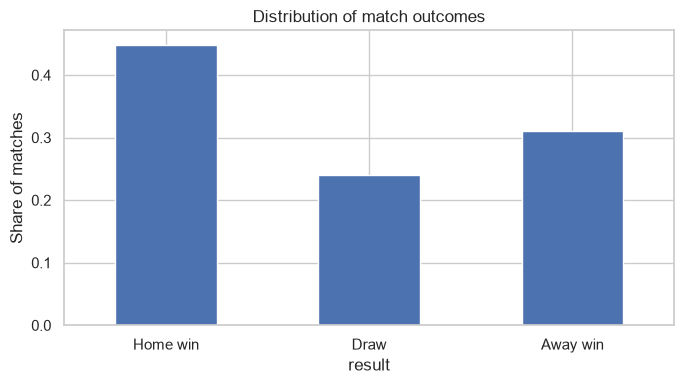

In [5]:
outcome_share = matches["result"].value_counts(normalize=True).reindex(["H", "D", "A"])
ax = outcome_share.plot(kind="bar", figsize=(7, 4))
ax.set_xticklabels(["Home win", "Draw", "Away win"], rotation=0)
ax.set_ylabel("Share of matches")
ax.set_title("Distribution of match outcomes")
plt.tight_layout()
plt.show()

## 3. Build pre-match features

For each team, calculate averages over its previous five matches: points, goals scored, goals conceded, goal difference, win rate and draw rate. The features are shifted by construction: the current match result is only added to a team's history after its predictors have been recorded.

The first appearance of a team uses neutral cold-start priors. These are not learned from the match being predicted.

In [6]:
features = build_features(matches, window=5)
features.head()

,date,season,home_team,away_team,target,home_points_avg,home_goals_for_avg,home_goals_against_avg,home_goal_difference_avg,home_win_rate,...,away_goals_against_avg,away_goal_difference_avg,away_win_rate,away_draw_rate,form_diff_points_avg,form_diff_goals_for_avg,form_diff_goals_against_avg,form_diff_goal_difference_avg,form_diff_win_rate,form_diff_draw_rate
0,2010-08-14,2010/11,Aston Villa,West Ham,H,1.0,1.2,1.2,0.0,0.333333,...,1.2,0.0,0.333333,0.333333,0.0,0.0,0.0,0.0,0.0,0.0
1,2010-08-14,2010/11,Blackburn,Everton,H,1.0,1.2,1.2,0.0,0.333333,...,1.2,0.0,0.333333,0.333333,0.0,0.0,0.0,0.0,0.0,0.0
2,2010-08-14,2010/11,Bolton,Fulham,D,1.0,1.2,1.2,0.0,0.333333,...,1.2,0.0,0.333333,0.333333,0.0,0.0,0.0,0.0,0.0,0.0
3,2010-08-14,2010/11,Chelsea,West Brom,H,1.0,1.2,1.2,0.0,0.333333,...,1.2,0.0,0.333333,0.333333,0.0,0.0,0.0,0.0,0.0,0.0
4,2010-08-14,2010/11,Sunderland,Birmingham,D,1.0,1.2,1.2,0.0,0.333333,...,1.2,0.0,0.333333,0.333333,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
feature_cols = FEATURE_COLUMNS
print("Rows:", len(features))
print("Feature count:", len(feature_cols))
print("Missing feature values:", int(features[feature_cols].isna().sum().sum()))

Rows: 5700
Feature count: 18
Missing feature values: 0


## 4. Chronological split

Training uses seasons through 2020/21, validation uses 2021/22 and 2022/23, and the final test uses 2023/24 and 2024/25. This mirrors the real forecasting direction: past data is used to predict later matches.

In [8]:
train, valid, test = temporal_split(features)
for label, part in [("Train", train), ("Validation", valid), ("Test", test)]:
    print(f"{label:10s}: {len(part):5,d} matches | {part['date'].min().date()} to {part['date'].max().date()}")

Train     : 4,180 matches | 2010-08-14 to 2021-05-23
Validation:   760 matches | 2021-08-13 to 2023-05-28
Test      :   760 matches | 2023-08-11 to 2025-05-25


## 5. Compare models

The majority-class baseline sets a useful minimum standard. Logistic regression is an interpretable linear baseline, while random forest can capture non-linear relationships. Model selection uses validation macro F1, which weights the three outcome classes equally.

In [9]:
validation_metrics, test_results, selected_model, splits, test_predictions = compare_models(features)
display(validation_metrics)

,model,accuracy,balanced_accuracy,macro_f1
2,Random forest,0.442105,0.397157,0.392797
1,Logistic regression,0.502632,0.409190,0.354892
0,Majority-class baseline,0.456579,0.333333,0.208973


## 6. Held-out test evaluation

The selected model is refitted on the combined training and validation periods, then evaluated on the untouched test seasons. Do not use these final test results to tune features or model settings repeatedly.

In [10]:
print("Selected model:", test_results["selected_model_by_validation_macro_f1"])
print(json.dumps(test_results["test_metrics"], indent=2))
print("\nPer-class report:")
display(pd.DataFrame(test_results["classification_report"]).T)

Selected model: Random forest
{
  "accuracy": 0.4605263157894737,
  "balanced_accuracy": 0.4127272727272728,
  "macro_f1": 0.4023583404897564
}

Per-class report:


,precision,recall,f1-score,support
H,0.506562,0.584848,0.542897,330.000000
D,0.200000,0.120000,0.150000,175.000000
A,0.496350,0.533333,0.514178,255.000000
accuracy,0.460526,0.460526,0.460526,0.460526
macro avg,0.400971,0.412727,0.402358,760.000000
weighted avg,0.432546,0.460526,0.442791,760.000000


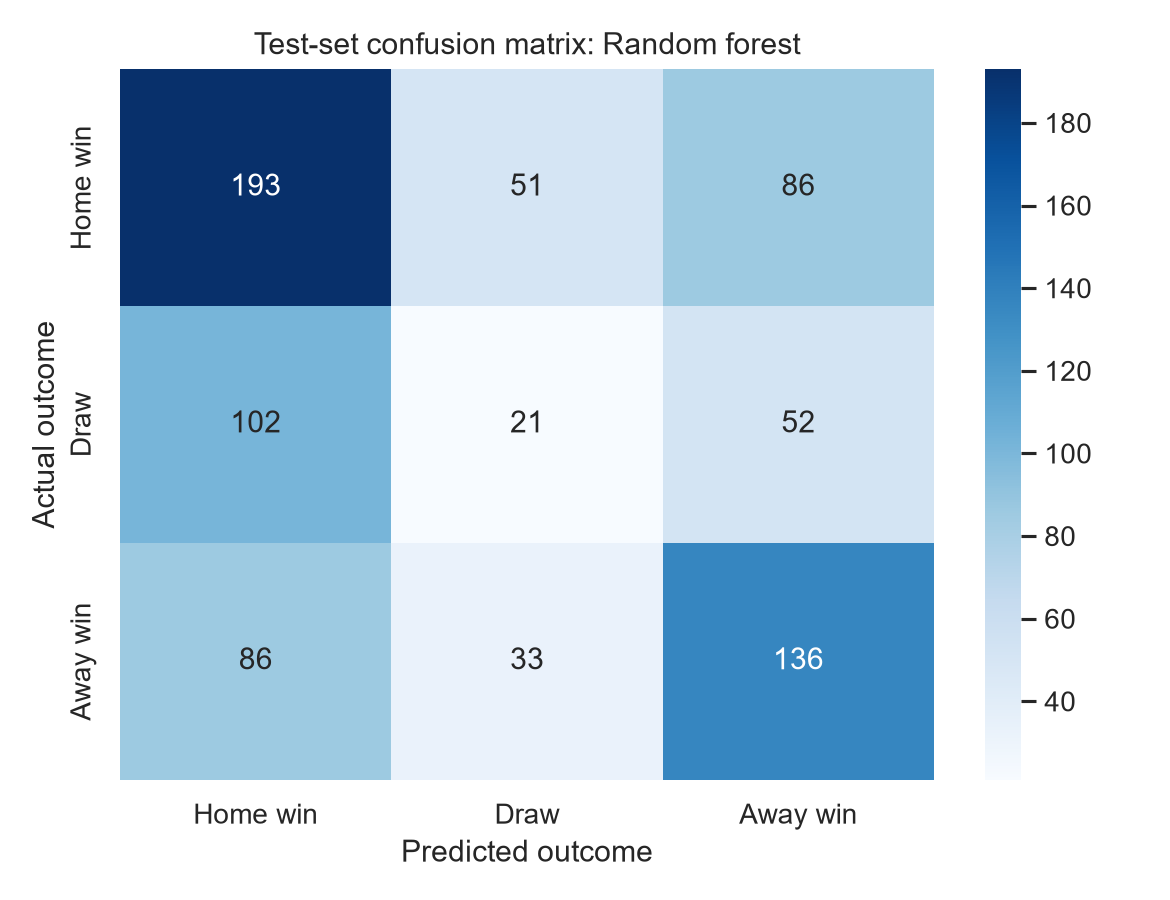

In [11]:
from IPython.display import Image, display
display(Image(filename="reports/test_confusion_matrix.png"))

## 7. Interpretation and limitations

Use the generated metrics and confusion matrix to answer:
1. Does either trained model beat the majority-class baseline on macro F1?
2. Which class is most often confused with another?
3. Is the improvement large enough to be meaningful, or only marginal?
4. What might change across seasons that this model cannot see?
5. How would you test whether a new feature adds value without introducing leakage?

This is a small, form-based model, not a complete football forecasting system. It excludes line-ups, injuries, player quality, transfers, managerial changes and market information. A good portfolio project explains these limitations rather than overselling its scores.